<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## 0. Settings
Trials from 01_sessions_setup: tables\trials_filtered.csv, only keep == True (60 sessions, 8,615 trials, rules R1–R5).
Session flags from final_sessions.csv (single_wt_session -> no short trials; short_vs_long).
Columns used: label (touch/correct/early/late/other), type (short/long), rt_s = release − tone, prev_outcome = label of the previous trial
in the session (computed before filtering), latency_to_press_s = previous trial_end → press, long_prob.
Figures -> main\figures\03_behaviour and data\amir_data.

<div>

In [14]:
# 0. SETTINGS 
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon
import warnings
warnings.simplefilter("ignore")

DATA_ROOT = r"O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data"
AMIR   = os.path.join(DATA_ROOT, "amir_data")
TABLES = r"C:\Users\ar687\Documents\GitHub\AmirAnalysis\main\tables"
FIGS   = os.path.join(os.path.dirname(TABLES), "figures", "03_behaviour")
os.makedirs(FIGS, exist_ok=True); os.makedirs(AMIR, exist_ok=True)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40)

final = pd.read_csv(os.path.join(TABLES, "final_sessions.csv"), dtype={"rat": str})
TR = pd.read_csv(os.path.join(TABLES, "trials_filtered.csv"), dtype={"rat": str}, low_memory=False)
for c in ["label", "type", "rt_s", "prev_outcome", "latency_to_press_s", "long_prob", "keep"]:
    assert c in TR.columns, f"trials_filtered.csv has no column '{c}' - rerun the trial filter in 01_sessions_setup"
K = TR[TR["keep"]].merge(final[["session", "single_wt_session", "short_vs_long"]], on="session", how="left")

print(f"kept trials: {len(K)} (expected 8615) | sessions: {K['session'].nunique()} (expected 60)")
print(pd.crosstab(K["rat"], [K["type"], K["label"]], margins=True).to_string())

kept trials: 8615 (expected 8615) | sessions: 60 (expected 60)
type     long              short               All
label correct early late correct early  late      
rat                                               
134       654   150  164     344    33   159  1504
135      1265  1704  196     892   183   419  4659
136       824   409  130     507   101   481  2452
All      2743  2263  490    1743   317  1059  8615


<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## 1. Helper: paired_test
Per session: median (or mean) of a value in condition a and in condition b (only sessions with >= min_n trials in both);
then Wilcoxon signed-rank test across sessions, per rat and all rats. Used by B1–B3 (session-level check).

<div>

In [8]:
# %%
# ── 1. HELPER: paired_test (per-session values, Wilcoxon across sessions) ──
def paired_test(df, value, cond_col, a, b, min_n=5, agg="median"):
    """Per session: median (or mean) of `value` in condition a and b (>= min_n trials each);
    Wilcoxon signed-rank across sessions, per rat and all rats."""
    g = df.groupby(["rat", "session", cond_col])[value].agg([agg, "size"]).reset_index()
    w = g.pivot_table(index=["rat", "session"], columns=cond_col, values=[agg, "size"])
    ok = (w[("size", a)] >= min_n) & (w[("size", b)] >= min_n)
    m = w.loc[ok, agg][[a, b]].reset_index()
    out = []
    for rat, d in list(m.groupby("rat")) + [("all", m)]:
        diff = d[b] - d[a]
        p = wilcoxon(d[a], d[b]).pvalue if len(d) >= 5 else np.nan
        out.append({"rat": rat, "n_sessions": len(d), f"median {a}": round(d[a].median(), 3),
                    f"median {b}": round(d[b].median(), 3), "median diff (b-a)": round(diff.median(), 3),
                    "sessions b>a": int((diff > 0).sum()), "wilcoxon p": round(p, 4) if p == p else np.nan})
    return pd.DataFrame(out), m

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## 2. B1 post-error slowing (Narayanan & Laubach 2008)
Are correct responses slower after an error? Correct trials only; previous trial correct, early or late (touch / other / first trial left out).
MAIN (decided 2026-10-22): linear mixed model on RT (ms), rt ~ after_late + after_early + long (+ rat in the pooled model),
random intercept per session, Wald p (raw); one model per rat + pooled. Short and long trials pooled (long as covariate).
CHECK: per-session medians after correct vs after error (early or late), Wilcoxon across sessions (>= 5 trials each).
RESULT v3 (2026-10-22, 8,675 trials): after late +35 ms [27, 44] (134 +47, 135 +36, 136 +32, all p < 0.0001);
after early +9 ms [2, 16] p = 0.015 (134 +29 p = 0.0006; 135, 136 n.s.).

<div>

In [9]:
# %%
# ── 2. B1 POST-ERROR SLOWING: mixed model (main) + per-session Wilcoxon (check) ──
import statsmodels.formula.api as smf

c = K[(K["label"] == "correct") & K["prev_outcome"].isin(["correct", "early", "late"])].copy()
c["rt_ms"]       = 1000 * c["rt_s"]
c["after_late"]  = (c["prev_outcome"] == "late").astype(int)
c["after_early"] = (c["prev_outcome"] == "early").astype(int)
c["long"]        = (c["type"] == "long").astype(int)
print("correct trials by previous outcome:", c["prev_outcome"].value_counts().to_dict())

rows = []
for rat, d in list(c.groupby("rat")) + [("all", c)]:
    formula = "rt_ms ~ after_late + after_early + long" + (" + C(rat)" if rat == "all" else "")
    m = smf.mixedlm(formula, d, groups=d["session"]).fit(reml=True, method=["lbfgs", "powell", "nm"], maxiter=2000)
    print(f"rat {rat}: converged = {m.converged} | session variance = {float(m.cov_re.iloc[0, 0]):.1f}")
    ci = m.conf_int()
    for term in ["after_late", "after_early"]:
        rows.append({"rat": rat, "effect": term, "n_trials": len(d), "n_sessions": d["session"].nunique(),
                     "delta_ms": round(m.params[term], 1), "ci_low": round(ci.loc[term, 0], 1),
                     "ci_high": round(ci.loc[term, 1], 1), "p": m.pvalues[term]})
B1_lmm = pd.DataFrame(rows)
print("\nB1 mixed model (difference to 'after correct', ms):")
print(B1_lmm.to_string(index=False, formatters={"p": "{:.2g}".format}))
B1_lmm.to_csv(os.path.join(TABLES, "B1_post_error_slowing_lmm.csv"), index=False)

# check: per-session medians, Wilcoxon (after correct vs after early/late together)
c["prev_err"] = np.where(c["prev_outcome"] == "correct", "after correct", "after error")
B1, B1_sessions = paired_test(c, "rt_s", "prev_err", "after correct", "after error")
print("\nB1 check, per-session median RT (s), Wilcoxon:")
print(B1.to_string(index=False))
B1.to_csv(os.path.join(TABLES, "B1_post_error_slowing.csv"), index=False)

correct trials by previous outcome: {'correct': 2429, 'early': 1154, 'late': 599}
rat 134: converged = True | session variance = 0.0
rat 135: converged = True | session variance = 0.0
rat 136: converged = True | session variance = 689.1
rat all: converged = True | session variance = 0.0

B1 mixed model (difference to 'after correct', ms):
rat      effect  n_trials  n_sessions  delta_ms  ci_low  ci_high       p
134  after_late       940          11      47.4    32.0     62.7 1.4e-09
134 after_early       940          11      29.0    12.5     45.4 0.00056
135  after_late      2052          29      35.5    21.2     49.7   1e-06
135 after_early      2052          29       5.4    -4.0     14.8    0.26
136  after_late      1190          20      32.2    18.4     46.0 4.5e-06
136 after_early      1190          20       3.3   -10.1     16.7    0.62
all  after_late      4182          60      35.3    26.8     43.8   5e-16
all after_early      4182          60       8.7     1.7     15.6   0.015

B

C:\Users\ar687\AppData\Local\Temp\ipykernel_22532\2856216231.py:15: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  m = smf.mixedlm(formula, d, groups=d["session"]).fit(reml=True, method=["lbfgs", "powell", "nm"], maxiter=2000)
C:\Users\ar687\AppData\Local\Temp\ipykernel_22532\2856216231.py:15: SingularMatrixWarning: The random effects covariance matrix is singular.
  m = smf.mixedlm(formula, d, groups=d["session"]).fit(reml=True, method=["lbfgs", "powell", "nm"], maxiter=2000)
C:\Users\ar687\AppData\Local\Temp\ipykernel_22532\2856216231.py:15: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
  m = smf.mixedlm(formula, d, groups=d["session"]).fit(reml=True, method=["lbfgs", "powell", "nm"], maxiter=2000)
C:\Users\ar687\AppData\Local\Temp\ipykernel_22532\2856216231.py:15: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  m = smf.mixedlm(formula, d, groups=d["session"]).fit(reml=True

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## 3. B2 early releases after an error (Donnelly et al. 2014)
Is the next trial more often an early release after an error? Kept trials (correct / early / late); previous trial correct, early or late.
MAIN (as before): per session, share of early releases after correct vs after error (early or late together), >= 10 trials each,
Wilcoxon across sessions, per rat and all rats.
CHECK (trial level, like B1): logistic model early ~ after_late + after_early + long (+ rat), GEE with sessions as clusters
-> odds ratio vs after correct.
RESULT 2026-10-21 (old filter, 59 sessions): FEWER early releases after an error, −3.2 %-points, 20/56 sessions higher, p = 0.011.

<div>

In [10]:
# %%
# ── 3. B2 EARLY RELEASES AFTER AN ERROR: per-session Wilcoxon (main) + trial-level GEE (check) ──
import statsmodels.api as sm

d = K[K["prev_outcome"].isin(["correct", "early", "late"])].copy()
d["is_early"]    = (d["label"] == "early").astype(int)
d["prev_err"]    = np.where(d["prev_outcome"] == "correct", "after correct", "after error")
d["after_late"]  = (d["prev_outcome"] == "late").astype(int)
d["after_early"] = (d["prev_outcome"] == "early").astype(int)
d["long"]        = (d["type"] == "long").astype(int)
print("trials by previous outcome:", d["prev_outcome"].value_counts().to_dict())
print("share early after correct / after error (all trials pooled): "
      f"{d.loc[d.prev_err == 'after correct', 'is_early'].mean():.3f} / {d.loc[d.prev_err == 'after error', 'is_early'].mean():.3f}")

# main: per-session shares, Wilcoxon
B2, B2_sessions = paired_test(d, "is_early", "prev_err", "after correct", "after error", min_n=10, agg="mean")
print("\nB2 share of early releases per session (median over sessions), after correct vs after error:")
print(B2.to_string(index=False))
B2.to_csv(os.path.join(TABLES, "B2_early_after_error.csv"), index=False)

# check: trial-level logistic GEE, sessions as clusters
rows = []
for rat, x in list(d.groupby("rat")) + [("all", d)]:
    formula = "is_early ~ after_late + after_early + long" + (" + C(rat)" if rat == "all" else "")
    g = smf.gee(formula, groups="session", data=x, family=sm.families.Binomial(),
                cov_struct=sm.cov_struct.Exchangeable()).fit()
    ci = g.conf_int()
    for term in ["after_late", "after_early"]:
        rows.append({"rat": rat, "effect": term, "n_trials": len(x), "n_sessions": x["session"].nunique(),
                     "odds_ratio": round(np.exp(g.params[term]), 2), "ci_low": round(np.exp(ci.loc[term, 0]), 2),
                     "ci_high": round(np.exp(ci.loc[term, 1]), 2), "p": g.pvalues[term]})
B2_gee = pd.DataFrame(rows)
print("\nB2 check, trial-level GEE (odds ratio vs after correct; < 1 = fewer early releases):")
print(B2_gee.to_string(index=False, formatters={"p": "{:.2g}".format}))
B2_gee.to_csv(os.path.join(TABLES, "B2_early_after_error_gee.csv"), index=False)

trials by previous outcome: {'correct': 4146, 'early': 2438, 'late': 1431}
share early after correct / after error (all trials pooled): 0.281 / 0.315

B2 share of early releases per session (median over sessions), after correct vs after error:
rat  n_sessions  median after correct  median after error  median diff (b-a)  sessions b>a  wilcoxon p
134          11                 0.120               0.136              0.002             6      0.9658
135          28                 0.408               0.400             -0.022            11      0.2642
136          18                 0.219               0.177             -0.043             3      0.0814
all          57                 0.268               0.205             -0.024            20      0.0521

B2 check, trial-level GEE (odds ratio vs after correct; < 1 = fewer early releases):
rat      effect  n_trials  n_sessions  odds_ratio  ci_low  ci_high       p
134  after_late      1414          11        1.13    0.87     1.46    0.37
134 a

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## 4. B3 latency to press before early vs correct trials (Donnelly et al. 2014)
Latency to press = previous trial_end → this press (behaviour clock, computed before filtering). Kept early and correct trials.
MAIN (as before): per-session median latency before correct vs before early (>= 5 trials each), Wilcoxon across sessions.
CHECK (trial level): mixed model log10(latency) ~ early + long (+ rat), random intercept per session -> ratio early / correct.
RESULT 2026-10-21 (old filter): no difference (+0.1 s, p = 0.78).

<div>

In [15]:
# %%
# ── 4. B3 LATENCY TO PRESS: before early vs before correct (Wilcoxon main + trial-level mixed model check) ──


d = K[K["label"].isin(["correct", "early"]) & K["latency_to_press_s"].notna()].copy()
print(f"trials: {len(d)} | latency (s) min {d['latency_to_press_s'].min():.2f}, "
      f"median {d['latency_to_press_s'].median():.2f}, 95th pct {d['latency_to_press_s'].quantile(.95):.1f}, "
      f"max {d['latency_to_press_s'].max():.0f} | <= 0: {(d['latency_to_press_s'] <= 0).sum()}")
d = d[d["latency_to_press_s"] > 0]

# main: per-session medians, Wilcoxon
B3, B3_sessions = paired_test(d, "latency_to_press_s", "label", "correct", "early")
print("\nB3 median latency to press before correct vs before early trials (s):")
print(B3.to_string(index=False))
B3.to_csv(os.path.join(TABLES, "B3_latency_to_press.csv"), index=False)

# check: trial level, log10 latency (latencies are skewed: long pauses)
d["log_lat"] = np.log10(d["latency_to_press_s"])
d["early"]   = (d["label"] == "early").astype(int)
d["long"]    = (d["type"] == "long").astype(int)
rows = []
for rat, x in list(d.groupby("rat")) + [("all", d)]:
    formula = "log_lat ~ early + long" + (" + C(rat)" if rat == "all" else "")
    m = smf.mixedlm(formula, x, groups=x["session"]).fit(reml=True, method=["lbfgs", "powell", "nm"], maxiter=2000)
    ci = m.conf_int()
    rows.append({"rat": rat, "n_trials": len(x), "n_sessions": x["session"].nunique(), "converged": m.converged,
                 "ratio_early_vs_correct": round(10 ** m.params["early"], 3),
                 "ci_low": round(10 ** ci.loc["early", 0], 3), "ci_high": round(10 ** ci.loc["early", 1], 3),
                 "p": m.pvalues["early"]})
B3_lmm = pd.DataFrame(rows)
print("\nB3 check, trial-level mixed model (ratio of latency before early / before correct; < 1 = faster before early):")
print(B3_lmm.to_string(index=False, formatters={"p": "{:.2g}".format}))
B3_lmm.to_csv(os.path.join(TABLES, "B3_latency_to_press_lmm.csv"), index=False)

trials: 7031 | latency (s) min 0.03, median 8.98, 95th pct 28.0, max 3721 | <= 0: 0

B3 median latency to press before correct vs before early trials (s):
rat  n_sessions  median correct  median early  median diff (b-a)  sessions b>a  wilcoxon p
134          10           8.482          9.00             -0.002             5      0.6953
135          28           8.290          8.50              0.067            15      0.4515
136          19          11.875         11.92              0.045            10      0.6507
all          57           9.280          9.28              0.055            30      0.5433

B3 check, trial-level mixed model (ratio of latency before early / before correct; < 1 = faster before early):
rat  n_trials  n_sessions  converged  ratio_early_vs_correct  ci_low  ci_high     p
134      1174          11       True                   1.070   0.980    1.168  0.13
135      4024          29       True                   1.033   0.992    1.075  0.12
136      1833          20 

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## 6. Label checks (all trials of the final sessions, and kept trials)
1. Hold: trials.csv hold_duration = release − press?
2. Touch vs early: every touch is also labelled early in trials.csv; is_touch == hold < 0.1 s; no early label with hold < 0.1 s.
3. Labels per trial: only double label = touch + early.
4. Response window (kept): correct rt 0–0.5 s, late rt > 0.5 s; correct and late never overlap within a session.
5. full_hold (kept): early ↔ full_hold == 0 (edge-zone early trials with full_hold ≠ 0 are removed by R5).
6. Press time (kept): from TTL vs from press_np_s, per session.
RESULT 2026-10-17 (old filter, timing_mismatch only flagged): 81 correct outside 0–0.5 s, 72 early with full_hold ≠ 0, correct/late overlap in 7 sessions.

<div>

In [17]:
# %%
# ── 6. LABEL CHECKS ──
A = TR.copy()                                                          # all trials of the 60 final sessions
A["hold_s"] = A["release"] - A["press"]

# 1. hold
print("1. max |hold_duration − (release − press)| (s):", round((A["hold_duration"] - A["hold_s"]).abs().max(), 4))

# 2. touch vs early
touch = A["is_touch"].astype(bool)
print("\n2. touch trials:", touch.sum(), "| of them labelled early in trials.csv:", (touch & (A["early"] == 1)).sum())
print("   early label (ours) with hold < 0.1 s:", ((A["label"] == "early") & (A["hold_s"] < 0.1)).sum())
print(pd.crosstab(touch, A["hold_s"] < 0.1, rownames=["is_touch"], colnames=["hold < 0.1 s"]).to_string())

# 3. labels per trial
L = pd.DataFrame({"touch": touch, "correct": A["correct"] == 1, "early": A["early"] == 1, "late": A["late"] == 1})
combo = L.apply(lambda r: " + ".join(c for c in L.columns if r[c]) or "(none)", axis=1)
print("\n3. label combinations in trials.csv:"); print(combo.value_counts().to_string())

# 4. response window (kept trials)
cl = K[K["label"].isin(["correct", "late"])]
print("\n4. rt_s (s) of kept correct / late trials:")
print(cl.groupby(["label", "type"])["rt_s"].describe()[["count", "min", "50%", "max"]].round(3).to_string())
print("   correct with rt outside 0–0.5 s:", (~cl.loc[cl["label"] == "correct", "rt_s"].between(0, 0.5)).sum(),
      "| late with rt <= 0.5 s:", (cl.loc[cl["label"] == "late", "rt_s"] <= 0.5).sum())
w = cl.groupby(["session", "label"])["rt_s"].agg(["max", "min"]).unstack("label")
overlap = (w[("max", "correct")] >= w[("min", "late")]).sum()
print("   sessions where correct and late rt overlap:", int(overlap))

# 5. full_hold (kept trials)
print("\n5. kept trials, full_hold == 0 by label:")
print(pd.crosstab(K["label"], K["full_hold"] == 0, colnames=["full_hold == 0"]).to_string())

# 6. press time (kept trials)
print("\n6. kept trials with press from TTL:", K["press_from_ttl"].sum(), "| from press_np_s:", (~K["press_from_ttl"]).sum())
noTTL = K[~K["press_from_ttl"]].groupby(["rat", "session"]).size().sort_values(ascending=False)
print("   sessions with presses from press_np_s:", len(noTTL)); print(noTTL.head(10).to_string())

1. max |hold_duration − (release − press)| (s): 0.0

2. touch trials: 656 | of them labelled early in trials.csv: 656
   early label (ours) with hold < 0.1 s: 0
hold < 0.1 s  False  True 
is_touch                  
False          9221      0
True              0    656

3. label combinations in trials.csv:
correct          4745
early            2771
late             1671
touch + early     656
(none)             34

4. rt_s (s) of kept correct / late trials:
                count   min   50%   max
label   type                           
correct long   2743.0  0.01  0.29  0.50
        short  1743.0  0.01  0.33  0.50
late    long    490.0  0.51  0.74  8.56
        short  1059.0  0.51  1.02  6.94
   correct with rt outside 0–0.5 s: 0 | late with rt <= 0.5 s: 0
   sessions where correct and late rt overlap: 0

5. kept trials, full_hold == 0 by label:
full_hold == 0  False  True 
label                       
correct          4486      0
early               0   2580
late             1549      

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

### Note: very fast correct responses
269 of 4,486 kept correct trials (6 %) have rt < 0.12 s (fastest 0.01 s after the tone). Probably releases timed in advance
rather than reactions to the tone. Kept, because the rule "correct rt >= 0.12 s" was removed on 2026-10-22.
All kept correct trials: rt 0.01–0.50 s; late trials: rt 0.51–8.56 s.

<div>

In [18]:
print("kept correct trials with rt < 0.12 s:", (K.loc[K["label"] == "correct", "rt_s"] < 0.12).sum(), "of", (K["label"] == "correct").sum())

kept correct trials with rt < 0.12 s: 269 of 4486


<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## 7. Performance per rat
Share of correct / early / late per rat, short and long trials, as 100 % bars (n = kept trials).
Saved: figures\03_behaviour\outcomes_per_rat.png and data\amir_data\outcomes_per_rat.png.

<div>

counts (correct, early, late):
label      correct  early  late
rat type                       
134 long       654    150   164
    short      344     33   159
135 long      1265   1704   196
    short      892    183   419
136 long       824    409   130
    short      507    101   481


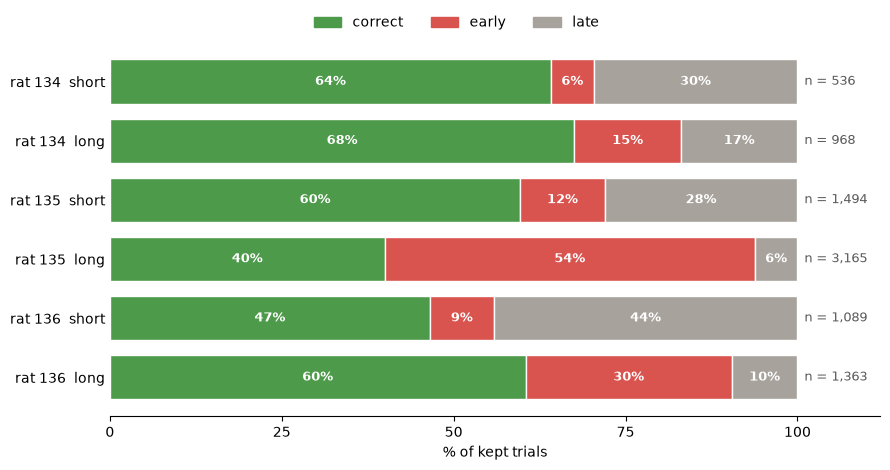

In [22]:
# %%
# ── 7. SLIDE D: outcomes per rat — horizontal 100 % bars, short and long (kept trials) ──
OUT = ["correct", "early", "late"]
COL = {"correct": "#4c9a4a", "early": "#d9534f", "late": "#a7a29c"}
cnt = pd.crosstab([K["rat"], K["type"]], K["label"]).reindex(columns=OUT, fill_value=0)
print("counts (correct, early, late):"); print(cnt.to_string())

rows = [(rat, typ) for rat in sorted(K["rat"].unique()) for typ in ["short", "long"] if (rat, typ) in cnt.index]
fig, ax = plt.subplots(figsize=(9, 0.6 * len(rows) + 1.2))
for i, (rat, typ) in enumerate(rows):
    n = cnt.loc[(rat, typ)]; tot = n.sum(); left = 0
    for o in OUT:
        w = 100 * n[o] / tot
        ax.barh(i, w, left=left, color=COL[o], edgecolor="white", height=0.75)
        if w >= 6:
            ax.text(left + w / 2, i, f"{w:.0f}%", ha="center", va="center", color="white", fontsize=9, fontweight="bold")
        left += w
    ax.text(101, i, f"n = {tot:,}", va="center", fontsize=9, color="0.35")
ax.set_yticks(range(len(rows))); ax.set_yticklabels([f"rat {r}  {t}" for r, t in rows], fontsize=10)
ax.invert_yaxis(); ax.set_xlim(0, 112); ax.set_xticks([0, 25, 50, 75, 100]); ax.set_xlabel("% of kept trials")
for sp in ("top", "right", "left"): ax.spines[sp].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=COL[o]) for o in OUT], labels=OUT,
          ncol=3, frameon=False, loc="lower center", bbox_to_anchor=(0.45, 1.0))
fig.tight_layout()
fig.savefig(os.path.join(FIGS, "performance_per_rat.png"), dpi=300, facecolor="white", bbox_inches="tight")
fig.savefig(os.path.join(AMIR, "performance_per_rat.png"), dpi=300, facecolor="white", bbox_inches="tight")
plt.show()

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## 9. Summary of the behaviour part (2026-10-23)

**Data:** 63 usable sessions → 60 final (3 WT-manipulation sessions of rat 134 excluded): rat 134: 11, 135: 29, 136: 20.
7 single-WT sessions (only 1.0 s: rat 135 ×6, rat 134 ×1) kept, but not used for short vs long (53 sessions).
All long_prob blocks kept. 9 sessions with sync_ok False kept (trials without timing are removed by R1).

**Definitions**
- label: touch (is_touch = hold < 0.1 s, checked first) / correct (release 0–0.5 s after tone) / early (before tone) / late (> 0.5 s after tone) / other
- type from wt (0.3 short, 1.0 long), not from the `long` column
- Neural clock: press = press_ttl_np_s, else press_np_s; tone and release = press + MA interval
- rt_s = release − tone; prev_outcome = label of the previous trial in the session; latency_to_press_s = previous trial_end → press (both computed before filtering)

**Trial funnel (01_sessions_setup, tables\trial_funnel.csv):** start 9,877 → R1 no press time −377 → R2 touch −633 → R3 early with hold > 1.05 s −0
→ R4 other −30 → R5 timing_mismatch −222 → **8,615 kept** (rat 134: 1,504, 135: 4,659, 136: 2,452), all 60 sessions keep trials.
Press from TTL 7,851, from press_np_s 764 (26 sessions, mostly the 4 low-TTL sessions).

**Label checks:** all consistent after the filter: hold_duration = release − press; all 656 touches are labelled early in trials.csv;
kept correct rt 0.01–0.50 s, late 0.51–8.56 s, no overlap in any session; kept early trials all full_hold = 0.
269 of 4,486 correct trials (6 %) have rt < 0.12 s (probably timed in advance), kept.

**Behaviour results** (main = trial-level models; check = per-session Wilcoxon)
- **B1 post-error slowing** (mixed model, RT of correct trials): after a late error +35 ms [27, 44] (134 +47, 135 +36, 136 +32; all p < 1e-5);
  after an early error +9 ms [2, 16], p = 0.015, only rat 134 (+29 ms, p = 0.0006). Wilcoxon: +12 ms, 39/58 sessions, p = 0.004.
- **B2 early releases after an error** (GEE, odds ratio vs after correct): after a late error FEWER early releases, OR 0.70, p = 0.0002
  (135 0.64, 136 0.65; 134 n.s.); after an early error no change (OR 0.91, p = 0.24). Wilcoxon (both errors together): −2.4 %-points, 20/57, p = 0.052.
- **B3 latency to press before early vs correct:** no faster pressing before early trials. Wilcoxon p = 0.54;
  trial model ratio 1.04 [1.00, 1.08], p = 0.039 (slightly longer, opposite to Donnelly 2014, no rat alone significant).
- Together: after a late error the rats hold longer (slower correct responses and fewer early releases), after an early error only rat 134 slows down.

**Open questions (supervisor / pipeline author):** how the MA decides correct vs late; is the MA delay the same for press and release;
rule behind sync_ok and meaning of ma_tdt_lag_s; how press TTL is matched to trials outside the sync span; how channel_regions.csv
was made (tilt = 0); MA version per session (reward_size unit); tone-volume sessions; how long_prob blocks switch (and the 0.01 / 0.02 values).

<div>